<a href="https://colab.research.google.com/github/Bharath-2810/unit-test-2/blob/main/unittest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [ ]:
import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (111, 60)
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.69   1.82  ...    8.03    7.94    8.11    8.26    8.15    8.07    7.35   
3  70.25  73.22  ...   93.59   92.69   92.62   92.97   96.37   95.68   88.64   
4  79.41  83.16  ...  116.04  115.10  115.07  115.76  119.25  118.40  109.75   

     2021    2022    2023  
0     NaN     N

In [ ]:
print(df.columns.tolist())

['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


In [ ]:
print(df.head())
print(df.columns.tolist())

               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.69   1.82  ...    8.03    7.94    8.11    8.26    8.15    8.07    7.35   
3  70.25  73.22  ...   93.59   92.69   92.62   92.97   96.37   95.68   88.64   
4  79.41  83.16  ...  116.04  115.10  115.07  115.76  119.25  118.40  109.75   

     2021    2022    2023  
0     NaN     NaN     NaN  
1   13.92   

In [ ]:
# Remove rows where every column is empty
df = df.dropna(how="all")

# Remove spaces from country names
df["Country"] = df["Country"].astype(str).str.strip()

# Display available countries
print(df["Country"].tolist())

['Canada', 'Mexico', 'US', 'Total North America', 'Argentina', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Peru', 'Trinidad & Tobago', 'Venezuela', 'Central America', 'Other Caribbean', 'Other South America', 'Total S. & Cent. America', 'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'North Macedonia', 'Norway', 'Poland', 'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'Ukraine', 'United Kingdom', 'Other Europe', 'Total Europe', 'Azerbaijan', 'Belarus', 'Kazakhstan', 'Russian Federation', 'Turkmenistan', 'USSR', 'Uzbekistan', 'Other CIS', 'Total CIS', 'Iran', 'Iraq', 'Israel', 'Kuwait', 'Oman', 'Qatar', 'Saudi Arabia', 'United Arab Emirates', 'Other Middle East', 'Total Middle East', 'Algeria', 'Egypt', 'Morocco', 'South Africa', 'Eastern Africa', 'Middle Africa', 

In [ ]:
print(df[df["Country"].str.lower() == "india"])

   Country  1965  1966  1967  1968  1969  1970  1971  1972  1973  ...   2014  \
91   India  2.23  2.30  2.37  2.53  2.81  2.75  2.86  3.01  3.07  ...  27.59   

     2015   2016   2017   2018   2019   2020   2021   2022   2023  
91  28.55  29.83  30.96  32.72  33.54  31.78  34.51  36.37  39.02  

[1 rows x 60 columns]


In [ ]:
india = df[df["Country"] == "India"].copy()

india = india.melt(
    id_vars=["Country"],
    var_name="year",
    value_name="energy_consumption"
)

india["year"] = pd.to_numeric(india["year"])
india["energy_consumption"] = pd.to_numeric(
    india["energy_consumption"], errors="coerce"
)

india = india.dropna(
    subset=["energy_consumption"]
).sort_values("year").reset_index(drop=True)

print(india.head())
print(india.tail())
print("Total records:", len(india))

  Country  year  energy_consumption
0   India  1965                2.23
1   India  1966                2.30
2   India  1967                2.37
3   India  1968                2.53
4   India  1969                2.81
   Country  year  energy_consumption
54   India  2019               33.54
55   India  2020               31.78
56   India  2021               34.51
57   India  2022               36.37
58   India  2023               39.02
Total records: 59


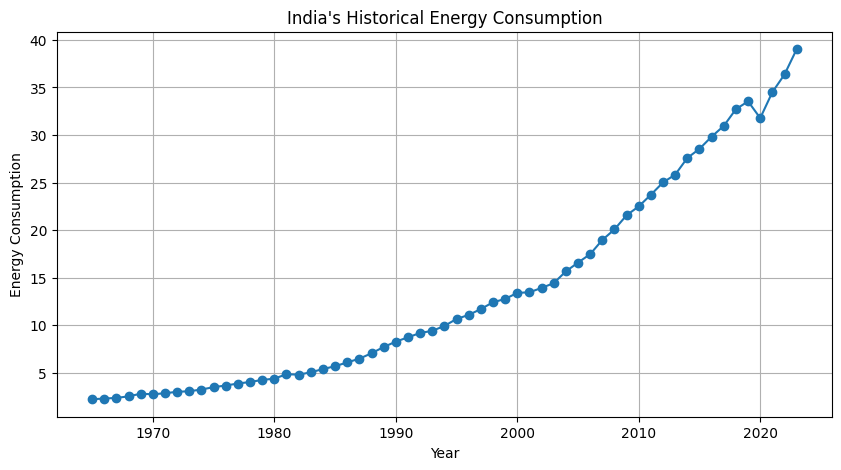

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(india["year"], india["energy_consumption"], marker="o")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.title("India's Historical Energy Consumption")
plt.grid(True)
plt.show()

In [19]:
india["energy_consumption"] = india["energy_consumption"].interpolate(
    method="linear",
    limit_area="inside"
)

india = india.dropna(
    subset=["energy_consumption"]
).reset_index(drop=True)

print(india.isnull().sum())
print("Total records:", len(india))

Country               0
year                  0
energy_consumption    0
dtype: int64
Total records: 59


In [20]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

data = india[["energy_consumption"]].values

split = int(len(data) * 0.8)

scaler = MinMaxScaler()

train = scaler.fit_transform(data[:split])
test = scaler.transform(data[split:])

print("Training records:", len(train))
print("Testing records:", len(test))

Training records: 47
Testing records: 12


In [21]:
def create_sequences(data, window=5):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])

    return np.array(X), np.array(y)


X_train, y_train = create_sequences(train, 5)

test_data = np.vstack([train[-5:], test])

X_test, y_test = create_sequences(test_data, 5)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42, 5, 1)
y_train shape: (42, 1)
X_test shape: (12, 5, 1)
y_test shape: (12, 1)


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential([
    LSTM(50, activation="tanh", input_shape=(5, 1)),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    shuffle=False,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1611
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1223     
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0919     
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0652 
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0416 
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0239 
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0151 
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0153 
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0188  
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0184 
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0143 
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0104 
Epoch 13/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0076 
Epoch 14/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0056 
Epoch 15/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0043 
Epoch 16/10

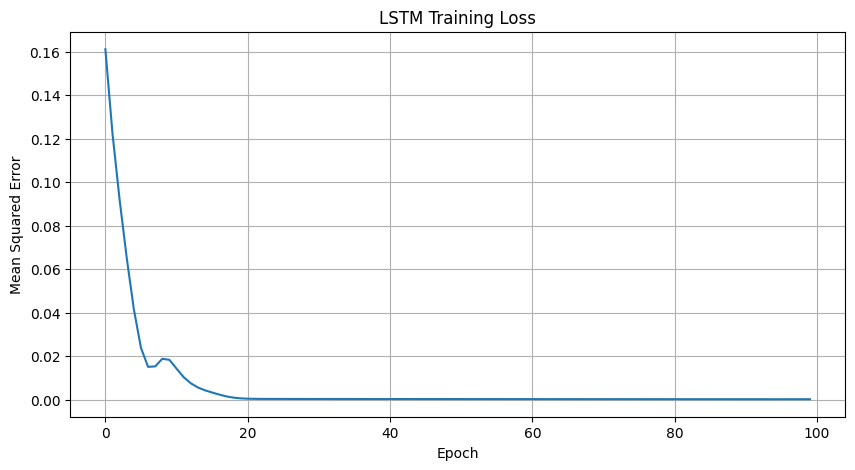

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Training Loss")
plt.grid(True)
plt.show()

In [25]:
predicted_scaled = model.predict(X_test)

predicted = scaler.inverse_transform(predicted_scaled)
actual = scaler.inverse_transform(y_test)

print("Actual values:", actual.flatten())
print("Predicted values:", predicted.flatten())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
Actual values: [25.02 25.84 27.59 28.55 29.83 30.96 32.72 33.54 31.78 34.51 36.37 39.02]
Predicted values: [25.448471 26.95106  28.410286 29.858662 31.341791 32.80952  34.2211
 35.817936 37.176697 38.13339  39.21498  40.312954]


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 1.9972371673583986
RMSE: 2.3974111857130964


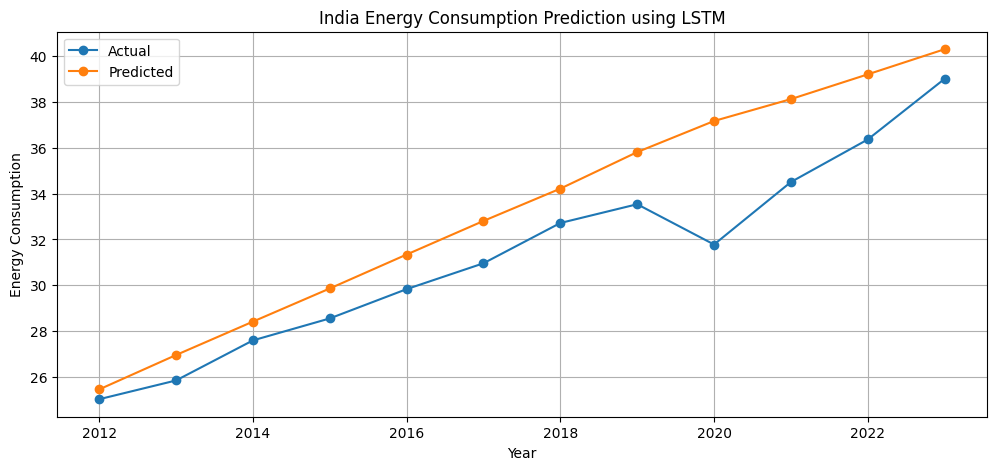

In [27]:
years = india["year"].iloc[split:].values

plt.figure(figsize=(12, 5))

plt.plot(years, actual.flatten(), marker="o", label="Actual")
plt.plot(years, predicted.flatten(), marker="o", label="Predicted")

plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.title("India Energy Consumption Prediction using LSTM")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
results = pd.DataFrame({
    "Year": years,
    "Actual": actual.flatten(),
    "Predicted": predicted.flatten()
})

results["Absolute Error"] = abs(
    results["Actual"] - results["Predicted"]
)

print(results.round(3).to_string(index=False))

 Year  Actual  Predicted  Absolute Error
 2012   25.02  25.448000           0.428
 2013   25.84  26.951000           1.111
 2014   27.59  28.410000           0.820
 2015   28.55  29.858999           1.309
 2016   29.83  31.341999           1.512
 2017   30.96  32.810001           1.850
 2018   32.72  34.221001           1.501
 2019   33.54  35.818001           2.278
 2020   31.78  37.176998           5.397
 2021   34.51  38.132999           3.623
 2022   36.37  39.215000           2.845
 2023   39.02  40.313000           1.293


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MAE: 1.9972
RMSE: 2.3974


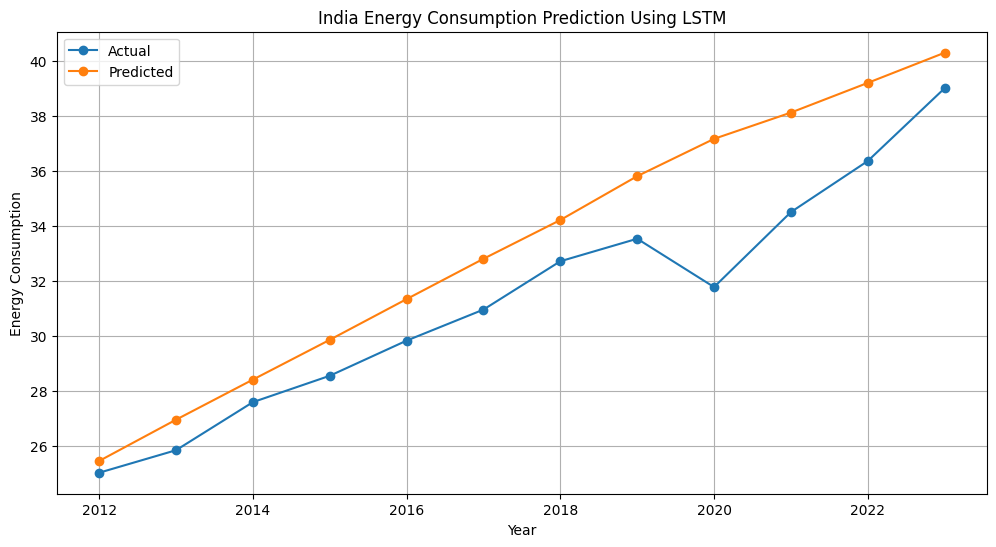

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(years, actual.flatten(), marker="o", label="Actual")
plt.plot(years, predicted.flatten(), marker="o", label="Predicted")

plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.title("India Energy Consumption Prediction Using LSTM")

plt.legend()
plt.grid(True)
plt.show()

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")

MAE: 1.9972
RMSE: 2.3974
R2 Score: 0.6476
R2 Percentage: 64.76 %


In [32]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(actual, predicted)
accuracy = (1 - mape) * 100

print("MAPE:", round(mape * 100, 2), "%")
print("Approximate Prediction Accuracy:", round(accuracy, 2), "%")

MAPE: 6.22 %
Approximate Prediction Accuracy: 93.78 %


In [33]:
import numpy as np

# Enter energy consumption for the previous 5 years
last_5_years = np.array([[34.51], [36.37], [39.02], [40.00], [41.00]])

# Normalize the input using the existing scaler
input_scaled = scaler.transform(last_5_years)

# Reshape for LSTM: (samples, timesteps, features)
input_scaled = input_scaled.reshape(1, 5, 1)

# Predict next year's consumption
prediction_scaled = model.predict(input_scaled, verbose=0)

# Convert prediction back to original scale
prediction = scaler.inverse_transform(prediction_scaled)

print("Predicted energy consumption:", round(float(prediction[0][0]), 2))

Predicted energy consumption: 44.66


In [34]:
predictions = scaler.inverse_transform(model.predict(X_test, verbose=0))

for i in range(len(actual)):
    print(
        f"Actual: {actual[i][0]:.2f} | "
        f"Predicted: {predictions[i][0]:.2f}"
    )

Actual: 25.02 | Predicted: 25.45
Actual: 25.84 | Predicted: 26.95
Actual: 27.59 | Predicted: 28.41
Actual: 28.55 | Predicted: 29.86
Actual: 29.83 | Predicted: 31.34
Actual: 30.96 | Predicted: 32.81
Actual: 32.72 | Predicted: 34.22
Actual: 33.54 | Predicted: 35.82
Actual: 31.78 | Predicted: 37.18
Actual: 34.51 | Predicted: 38.13
Actual: 36.37 | Predicted: 39.21
Actual: 39.02 | Predicted: 40.31


In [35]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    shuffle=False,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 222ms/step - loss: 1.8415e-04 - val_loss: 6.2322e-04
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 2.1382e-04 - val_loss: 0.0015
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 3.4256e-04 - val_loss: 0.0023
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 2.8544e-04 - val_loss: 0.0022
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 2.2305e-04 - val_loss: 0.0021
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 2.4247e-04 - val_loss: 0.0025
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.6173e-04 - val_loss: 0.0029
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 2.5852e-04 - val_loss: 0.0029
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 2.3017e-04 - val_loss: 0.0027
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 2.0377e-04 - val_loss: 0.0026
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.9505e-04 - val_loss: 0.0026


In [36]:
print("Epochs completed:", len(history.history["loss"]))

Epochs completed: 11


In [37]:
best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Epochs completed:", len(history.history["loss"]))
print("Best epoch:", best_epoch)
print("Best validation loss:", round(min(history.history["val_loss"]), 4))

Epochs completed: 11
Best epoch: 1
Best validation loss: 0.0006


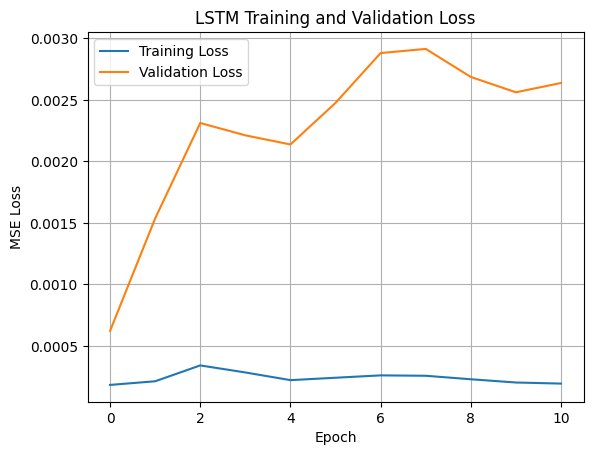

In [38]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(16, activation="tanh", input_shape=(5, 1)),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    shuffle=False,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - loss: 0.1328 - val_loss: 0.9358
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1112 - val_loss: 0.8438
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0994 - val_loss: 0.7649
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0906 - val_loss: 0.7123
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0839 - val_loss: 0.6712
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0741 - val_loss: 0.6410
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0708 - val_loss: 0.6198
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0697 - val_loss: 0.6039
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0676 - val_loss: 0.5912
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0669 - val_loss: 0.5784
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0655 - val_loss: 0.5682
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0645 - val_loss: 0.5589


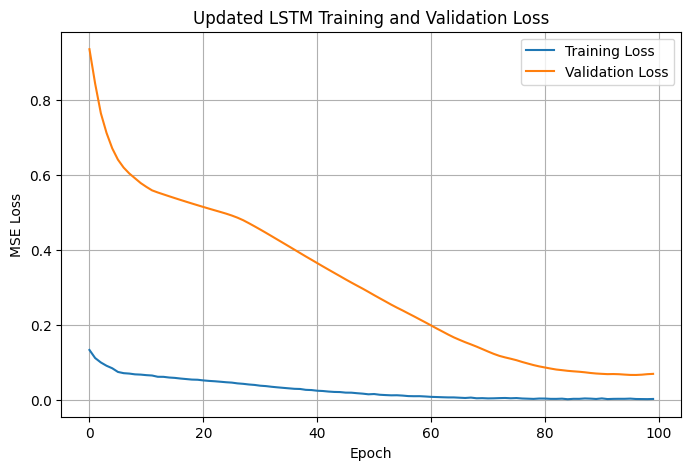

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Updated LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [41]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error, r2_score

predicted_scaled = model.predict(X_test, verbose=0)

predicted = scaler.inverse_transform(predicted_scaled)
actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = mean_absolute_percentage_error(actual, predicted) * 100
r2 = r2_score(actual, predicted)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("MAPE:", round(mape, 2), "%")
print("R2 Score:", round(r2, 4))

MAE: 14.1795
RMSE: 14.5177
MAPE: 44.76 %
R2 Score: -11.9221


In [42]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(50, activation="tanh", input_shape=(5, 1)),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [43]:
history = model.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=8,
    shuffle=False,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0648 - val_loss: 0.4783
Epoch 2/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0464 - val_loss: 0.3780
Epoch 3/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0324 - val_loss: 0.2886
Epoch 4/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0207 - val_loss: 0.2095
Epoch 5/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0123 - val_loss: 0.1393
Epoch 6/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0076 - val_loss: 0.0837
Epoch 7/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0073 - val_loss: 0.0469
Epoch 8/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0090 - val_loss: 0.0299
Epoch 9/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0095 - val_loss: 0.0269
Epoch 10/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0081 - val_loss: 0.0297
Epoch 11/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0063 - val_loss: 0.0322
Epoch 12/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0048 - val_lo

In [44]:
model = Sequential([
    LSTM(50, activation="tanh", input_shape=(5, 1)),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=8,
    shuffle=False,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.0695 - val_loss: 0.5124
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0505 - val_loss: 0.4091
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0350 - val_loss: 0.3154
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0228 - val_loss: 0.2311
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0138 - val_loss: 0.1586
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0088 - val_loss: 0.1004
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0080 - val_loss: 0.0604
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0098 - val_loss: 0.0385
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0111 - val_loss: 0.0311
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0104 - val_loss: 0.0320


In [45]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error, r2_score

predicted_scaled = model.predict(X_test, verbose=0)

predicted = scaler.inverse_transform(predicted_scaled)
actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = mean_absolute_percentage_error(actual, predicted) * 100
r2 = r2_score(actual, predicted)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("MAPE:", round(mape, 2), "%")
print("R2 Score:", round(r2, 4))

MAE: 7.6783
RMSE: 7.8375
MAPE: 24.37 %
R2 Score: -2.7661


In [46]:
print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nFirst 5 actual test values:")
print(scaler.inverse_transform(y_test[:5]).flatten())

Training sequences: (42, 5, 1)
Testing sequences: (12, 5, 1)
Training targets: (42, 1)
Testing targets: (12, 1)

First 5 actual test values:
[25.02 25.84 27.59 28.55 29.83]


In [47]:
print("Actual values:", actual.flatten()[:5])
print("Predicted values:", predicted.flatten()[:5])

Actual values: [25.02 25.84 27.59 28.55 29.83]
Predicted values: [19.150288 20.000137 20.827326 21.64297  22.489712]


In [48]:
print("Total data points:", len(data))
print("Training data points:", len(train))
print("Test data points:", len(test))

print("\nLast 5 training values:")
print(scaler.inverse_transform(train[-5:] if train.ndim == 2 else train[-5:].reshape(-1, 1)).flatten())

print("\nFirst 5 actual test values:")
print(scaler.inverse_transform(y_test[:5]).flatten())

Total data points: 59
Training data points: 47
Test data points: 12

Last 5 training values:
[18.97 20.08 21.57 22.5  23.73]

First 5 actual test values:
[25.02 25.84 27.59 28.55 29.83]


In [49]:
print("First test sequence (original scale):")
print(scaler.inverse_transform(X_test[0]).flatten())

print("\nActual target:")
print(scaler.inverse_transform(y_test[:1]).flatten())

print("\nPredicted target:")
print(scaler.inverse_transform(model.predict(X_test[:1], verbose=0)).flatten())

First test sequence (original scale):
[18.97 20.08 21.57 22.5  23.73]

Actual target:
[25.02]

Predicted target:


[19.150288]


In [50]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

np.random.seed(42)
tf.random.set_seed(42)

model = Sequential([
    LSTM(50, activation="tanh", input_shape=(5, 1)),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=8,
    shuffle=False,
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.1935
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1463     
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1057     
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0736 
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0468 
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0273 
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0172 
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0162 
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0194 
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0191 
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0149 
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0104 
Epoch 13/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0072 
Epoch 14/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0050 
Epoch 15/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0036 
Epoch 16/100
6/6 ━━━━━━

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predicted_scaled = model.predict(X_test, verbose=0)

predicted = scaler.inverse_transform(predicted_scaled)
actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100
r2 = r2_score(actual, predicted)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("MAPE:", round(mape, 2), "%")
print("R² Score:", round(r2, 4))

print("\nFirst 5 actual values:", actual[:5].flatten())
print("First 5 predicted values:", predicted[:5].flatten())

MAE: 1.3903
RMSE: 1.8198
MAPE: 4.36 %
R² Score: 0.797

First 5 actual values: [25.02 25.84 27.59 28.55 29.83]
First 5 predicted values: [25.334494 26.7301   28.093906 29.423548 30.80982 ]


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100
r2 = r2_score(actual, predicted)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("MAPE:", round(mape, 2), "%")
print("R² Score:", round(r2, 4))

MAE: 1.3903
RMSE: 1.8198
MAPE: 4.36 %
R² Score: 0.797


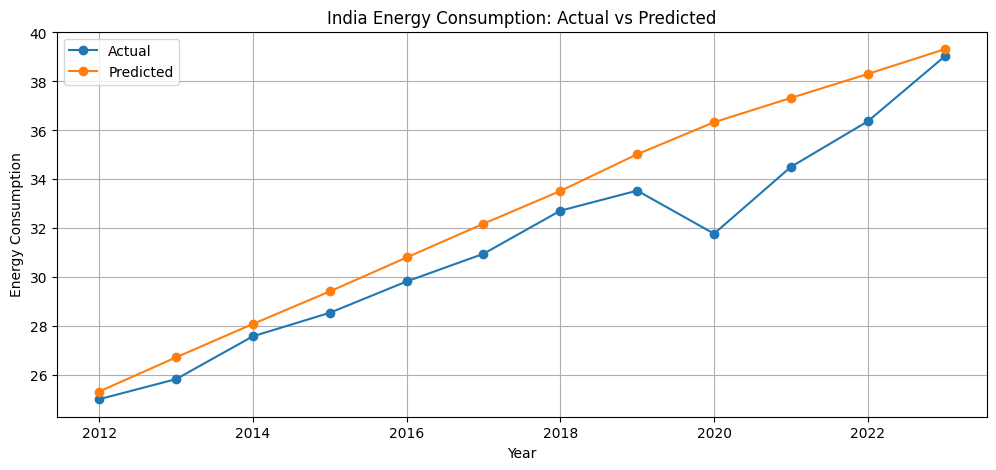

In [53]:
import matplotlib.pyplot as plt

years = india["year"].values[-len(actual):]

plt.figure(figsize=(12, 5))
plt.plot(years, actual.flatten(), marker="o", label="Actual")
plt.plot(years, predicted.flatten(), marker="o", label="Predicted")

plt.title("India Energy Consumption: Actual vs Predicted")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
import numpy as np

# Enter energy consumption for the previous 5 years
test_input = np.array([[18.97, 20.08, 21.57, 22.50, 23.73]])

# Scale the input using the same scaler used during training
test_scaled = scaler.transform(test_input.reshape(-1, 1))

# Reshape for LSTM: (samples, timesteps, features)
test_scaled = test_scaled.reshape(1, 5, 1)

# Predict the next year's consumption
prediction_scaled = model.predict(test_scaled, verbose=0)

# Convert prediction back to original scale
prediction = scaler.inverse_transform(prediction_scaled)

print("Previous 5 years:", test_input.flatten())
print("Predicted next year's energy consumption:", round(float(prediction[0][0]), 2))

Previous 5 years: [18.97 20.08 21.57 22.5  23.73]
Predicted next year's energy consumption: 25.33
